# 📣 Social Wave: Otimização de Campanhas de Marketing

## 1. Entendimento do Negócio e Contextualização

### 1.1 A empresa

A **Social Wave** é uma marca brasileira (fictícia) de roupas casuais que vende só pela internet. Ela nasceu em São Paulo em 2020 e cresceu apostando em anúncios nas redes sociais e nos buscadores. Hoje quase todas as vendas do site vêm de mídia paga, espalhada em 6 canais:

| Canal | Tipo | Papel na estratégia |
|---|---|---|
| Google Search | Anúncio na busca | Pegar quem já está procurando roupa |
| Google Display | Banners em sites | Lembrar a marca para quem já visitou o site |
| Meta Ads | Facebook e Instagram | Principal canal de vendas |
| TikTok Ads | Vídeos curtos | Alcançar o público jovem |
| YouTube Ads | Vídeos | Divulgar a marca |
| Pinterest Ads | Inspiração de moda | Público que procura ideias de look |

### 1.2 O problema

Em 2024 e 2025 o time de marketing dividiu a verba quase igual entre os canais, ajustando "no feeling". O investimento cresceu, mas o **CPA (custo por aquisição)**, ou seja, quanto a empresa gasta em anúncio para conseguir uma venda, subiu junto. A diretoria desconfia que tem canal recebendo dinheiro demais e canal recebendo de menos.

Para 2026 o orçamento de mídia vai continuar o mesmo de 2025. A pergunta da diretoria é direta: **dá para vender mais com o mesmo dinheiro?**

### 1.3 O teste A/B

Em novembro de 2025 o time testou um criativo novo no Meta Ads. As pessoas foram divididas por sorteio em dois grupos:

- **Grupo A (controle):** viu o criativo atual, uma foto do produto em fundo branco.
- **Grupo B (teste):** viu o criativo novo, um vídeo curto de um cliente usando a peça.

O criativo B parece ter vendido mais, mas o time não sabe se a diferença é real ou se foi sorte.

### 1.4 Perguntas de negócio

1. Quanto investimos e quanto retornou em cada canal (CPA e ROAS)?
2. Em que etapa do funil cada canal perde mais gente (CTR e taxa de conversão)?
3. Como investimento, conversões e CPA mudaram ao longo de 2024 e 2025?
4. A partir de que investimento cada canal começa a saturar, ou seja, cada real a mais traz menos vendas?
5. Como redistribuir o mesmo orçamento entre os canais para ter o máximo de conversões, e quanto o CPA cai com isso?
6. No teste A/B do Meta Ads, o criativo novo converte mais que o atual de verdade ou a diferença foi sorte?

### 1.5 Métricas usadas

| Métrica | O que é | Conta |
|---|---|---|
| Investimento | Quanto foi gasto em anúncios | soma do gasto |
| Impressões | Quantas vezes o anúncio apareceu | soma |
| Cliques | Quantas vezes clicaram no anúncio | soma |
| Conversões | Vendas que vieram do anúncio | soma |
| Receita | Valor das vendas que vieram do anúncio | soma |
| CTR | De cada 100 impressões, quantas viraram clique | cliques ÷ impressões |
| Taxa de conversão | De cada 100 cliques, quantos viraram venda | conversões ÷ cliques |
| CPA | Quanto custa conseguir uma venda | investimento ÷ conversões |
| ROAS | Quantos reais voltam para cada real investido | receita ÷ investimento |

### 1.6 Estrutura do projeto

    social-wave-campaign-optimization/
    ├── social_wave_campaign_optimization.ipynb
    ├── generate_data.py
    ├── channels.csv
    ├── campaigns.csv
    ├── daily_performance.csv
    ├── ab_test.csv
    ├── requirements.txt
    ├── README.md
    └── .gitignore

| Arquivo | Conteúdo |
|---|---|
| `social_wave_campaign_optimization.ipynb` | Notebook com todo o estudo de caso |
| `generate_data.py` | Script que gera as bases fictícias (semente fixa) |
| `channels.csv` | Cadastro dos 6 canais de mídia |
| `campaigns.csv` | Cadastro das campanhas de cada canal |
| `daily_performance.csv` | Resultado diário de cada campanha (investimento, impressões, cliques, conversões e receita) de 2024 e 2025 |
| `ab_test.csv` | Resultado de cada pessoa no teste A/B do Meta Ads (grupo, clicou, comprou) |
| `requirements.txt` | Bibliotecas e versões para reproduzir o projeto |

## 2. Bibliotecas utilizadas

| Biblioteca | Para que serve no projeto |
|---|---|
| `pandas` | Ler os arquivos e trabalhar com as tabelas |
| `numpy` | Contas numéricas |
| `sqlite3` | Rodar consultas SQL em um banco em memória |
| `matplotlib` e `seaborn` | Gráficos |

In [4]:
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='white')

## 3. Carregamento dos dados

As bases foram geradas pelo script `generate_data.py` e estão na raiz do projeto. São 4 arquivos:

- `channels.csv` e `campaigns.csv`: cadastros (quem é quem)
- `daily_performance.csv`: o resultado diário das campanhas
- `ab_test.csv`: o resultado de cada pessoa no teste A/B

In [7]:
channels = pd.read_csv('channels.csv')
campaigns = pd.read_csv('campaigns.csv')
performance = pd.read_csv('daily_performance.csv')
ab_test = pd.read_csv('ab_test.csv')

for name,df in [('channels', channels),('campaigns', campaigns), ('performance', performance), ('ab_test', ab_test)]:
    print(f'{name}: {df.shape[0]} linhas e {df.shape[1]} colunas')

channels: 6 linhas e 3 colunas
campaigns: 12 linhas e 5 colunas
performance: 8868 linhas e 7 colunas
ab_test: 40200 linhas e 5 colunas


In [8]:
display(channels.head())
print('\n')
display(campaigns.head())
print('\n')
display(performance.head())
print('\n')
display(ab_test.head())

,channel_id,channel_name,channel_type
0,CH01,Google Search,Busca
1,CH02,Google Display,Display
2,CH03,Meta Ads,Rede social
3,CH04,TikTok Ads,Rede social
4,CH05,YouTube Ads,Vídeo


,campaign_id,channel_id,campaign_name,campaign_type,start_date
0,CP01,CH01,Google Search - Prospecção,Prospecção,2024-01-01
1,CP02,CH01,Google Search - Remarketing,Remarketing,2024-01-01
2,CP03,CH02,Google Display - Prospecção,Prospecção,2024-01-01
3,CP04,CH02,Google Display - Remarketing,Remarketing,2024-01-01
4,CP05,CH03,Meta Ads - Prospecção,Prospecção,2024-01-01


,date,campaign_id,spend,impressions,clicks,conversions,revenue
0,2024-01-01,CP10,184.97,12923,59,5.0,1053.27
1,2024-01-01,CP01,410.72,9174,357,19.0,4130.42
2,2024-01-01,CP02,164.25,3705,140,9.0,1849.71
3,2024-01-01,CP03,472.63,65938,262,5.0,887.84
4,2024-01-01,CP04,180.66,20715,80,7.0,1344.73


,user_id,group,exposure_date,clicked,converted
0,U10582,A,2025-11-10,0,0
1,U26354,A,2025-11-22,0,0
2,U28211,B,2025-11-05,0,0
3,U09435,A,2025-11-05,0,0
4,U36696,B,2025-11-06,0,0


## 4. Descrição dos dados

### 4.1 Dicionário de dados

**channels.csv**

| Coluna | Descrição |
|---|---|
| `channel_id` | Código do canal (CH01 a CH06) |
| `channel_name` | Nome do canal |
| `channel_type` | Tipo do canal (Busca, Display, Rede social, Vídeo) |

**campaigns.csv**

| Coluna | Descrição |
|---|---|
| `campaign_id` | Código da campanha (CP01 a CP12) |
| `channel_id` | Canal onde a campanha roda |
| `campaign_name` | Nome da campanha |
| `campaign_type` | Prospecção (gente nova) ou Remarketing (quem já visitou o site) |
| `start_date` | Data de início da campanha |

**daily_performance.csv**

| Coluna | Descrição |
|---|---|
| `date` | Dia |
| `campaign_id` | Código da campanha |
| `spend` | Investimento do dia |
| `impressions` | Vezes que o anúncio apareceu |
| `clicks` | Cliques no anúncio |
| `conversions` | Vendas que vieram do anúncio |
| `revenue` | Valor dessas vendas |

**ab_test.csv**

| Coluna | Descrição |
|---|---|
| `user_id` | Código da pessoa |
| `group` | A (criativo atual, foto) ou B (criativo novo, vídeo) |
| `exposure_date` | Dia em que a pessoa viu o anúncio |
| `clicked` | 1 se clicou, 0 se não |
| `converted` | 1 se comprou, 0 se não |

### 4.2 Desempenho diário

Primeiro, os tipos de cada coluna e se tem valor vazio.

In [9]:
performance.info()

<class 'pandas.DataFrame'>
RangeIndex: 8868 entries, 0 to 8867
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         8868 non-null   str    
 1   campaign_id  8868 non-null   str    
 2   spend        8868 non-null   float64
 3   impressions  8868 non-null   int64  
 4   clicks       8868 non-null   int64  
 5   conversions  8808 non-null   float64
 6   revenue      8868 non-null   float64
dtypes: float64(3), int64(2), str(2)
memory usage: 485.1 KB


In [12]:
duplicated_rows = performance.duplicated().sum()
empty_conversions = performance['conversions'].isna().sum()
negative_spend = (performance['spend'] < 0).sum()
clicks_over_impressions = (performance['clicks'] > performance['impressions']).sum()
campaign_codes = performance['campaign_id'].unique()
expected_rows = performance['date'].unique() * len(campaigns)
rows_without_duplicates = len(performance) - duplicated_rows

print(f'Linhas duplicadas: {duplicated_rows}')
print('\n')
print(f'Conversões vazias: {empty_conversions}')
print('\n')
print(f'Gasto negativo: {negative_spend}')
print('\n')
print(f'Cliques maiores que impressões: {clicks_over_impressions}')
print('\n')
print(f'Códigos de campanha diferentes: {campaign_codes} (deveriam ser {len(campaigns)})')
print('\n')
print(f'Linhas sem duplicados: {rows_without_duplicates} de {expected_rows} esperadas')

Linhas duplicadas: 150


Conversões vazias: 60


Gasto negativo: 35


Cliques maiores que impressões: 25


Códigos de campanha diferentes: <StringArray>
[' CP10 ',   'CP01',   'CP02',   'CP03',   'CP04',   'CP05',   'CP06',
   'CP07',   'CP08',   'CP09',   'CP11',   'cp12', ' CP05 ', ' CP08 ',
   'CP10',   'CP12',   'cp06',  'CP-01', ' CP11 ',  'CP-02',   'cp07',
  'CP-04',  'CP-06',   'cp10',  'CP-11', ' CP04 ', ' CP06 ',   'cp08',
   'cp03', ' CP03 ',  'CP-08',   'cp04',  'CP-05', ' CP02 ',   'cp09',
 ' CP12 ',  'CP-07', ' CP09 ',   'cp01',  'CP-09', ' CP01 ',   'cp05',
  'CP-03',  'CP-10',   'cp02',  'CP-12', ' CP07 ',   'cp11']
Length: 48, dtype: str (deveriam ser 12)


Linhas sem duplicados: 8718 de <StringArray>
['2024-01-012024-01-012024-01-012024-01-012024-01-012024-01-012024-01-012024-01-012024-01-012024-01-012024-01-012024-01-01',
 '2024-01-022024-01-022024-01-022024-01-022024-01-022024-01-022024-01-022024-01-022024-01-022024-01-022024-01-022024-01-02',
 '2024-01-032024-01-03

In [13]:
sorted(performance['campaign_id'].unique())

[' CP01 ',
 ' CP02 ',
 ' CP03 ',
 ' CP04 ',
 ' CP05 ',
 ' CP06 ',
 ' CP07 ',
 ' CP08 ',
 ' CP09 ',
 ' CP10 ',
 ' CP11 ',
 ' CP12 ',
 'CP-01',
 'CP-02',
 'CP-03',
 'CP-04',
 'CP-05',
 'CP-06',
 'CP-07',
 'CP-08',
 'CP-09',
 'CP-10',
 'CP-11',
 'CP-12',
 'CP01',
 'CP02',
 'CP03',
 'CP04',
 'CP05',
 'CP06',
 'CP07',
 'CP08',
 'CP09',
 'CP10',
 'CP11',
 'CP12',
 'cp01',
 'cp02',
 'cp03',
 'cp04',
 'cp05',
 'cp06',
 'cp07',
 'cp08',
 'cp09',
 'cp10',
 'cp11',
 'cp12']

In [14]:
performance[performance['spend'] < 0].head()

,date,campaign_id,spend,impressions,clicks,conversions,revenue
93,2024-01-08,CP07,-178.00,17021,148,2.0,280.28
394,2024-02-02,CP05,-306.45,16404,176,11.0,2018.18
489,2024-02-10,CP01,-796.47,21567,836,21.0,4196.71
851,2024-03-11,CP01,-674.61,16586,644,25.0,5390.40
1207,2024-04-09,CP03,-495.40,65403,252,7.0,1272.44


### 4.3 Teste A/B

In [16]:
duplicated_rows = ab_test.duplicated().sum()
groups_per_user = ab_test.drop_duplicates().groupby('user_id')['group'].nunique()
users_in_both_groups = (groups_per_user > 1).sum()

print(f'Linhas duplicadas: {duplicated_rows}')
print('\n')
print(f'Pessoas nos dois grupos: {users_in_both_groups}')
print('\n')
print(f'Valores vazios: {ab_test.isna().sum().sum()}')
print('\n')
print(ab_test['group'].value_counts())

Linhas duplicadas: 80


Pessoas nos dois grupos: 120


Valores vazios: 0


group
A    20226
B    19974
Name: count, dtype: int64


### 4.4 Resumo dos problemas e decisões

| Base | Problema | Quantidade | Decisão |
|---|---|---|---|
| `daily_performance` | Linhas duplicadas | 150 | Remover |
| `daily_performance` | Código da campanha escrito de jeitos diferentes | 48 códigos para 12 campanhas | Padronizar: tirar espaços, deixar maiúsculo e tirar o hífen |
| `daily_performance` | Gasto negativo | 35 | Trocar o sinal. O anúncio rodou (tem impressões, cliques e vendas), só o sinal veio errado |
| `daily_performance` | Cliques maiores que impressões | 25 | Destrocar as duas colunas (vieram invertidas na exportação) |
| `daily_performance` | Conversões vazias | 60 | Estimar com cliques do dia × taxa de conversão da campanha |
| `daily_performance` | Dias faltando | 54 linhas | Manter sem preencher. Sem o gasto do dia, preencher seria inventar dado |
| `ab_test` | Linhas duplicadas | 80 | Remover |
| `ab_test` | Pessoas nos dois grupos | 120 | Tirar essas pessoas do teste. Elas viram os dois criativos e não dá pra saber qual influenciou a compra |

## 5. Limpeza

### 5.1 Desempenho diário

Seguindo as decisões da tabela 4.4, as correções vão para uma cópia da base (`performance_clean`) e a original fica intacta.

In [18]:
performance_clean = performance.drop_duplicates().copy()
performance_clean['campaign_id'] = (performance_clean['campaign_id'].str.strip().str.upper().str.replace('-',''))
performance_clean['spend'] = performance_clean['spend'].abs()
swapped = performance_clean['clicks'] > performance_clean['impressions']
performance_clean.loc[swapped, ['impressions', 'clicks']] = performance_clean.loc[swapped, ['clicks','impressions']].values

campaign_codes = performance_clean['campaign_id'].nunique()
negative_spend = (performance_clean['spend'] < 0).sum()
clicks_over_impressions = (performance_clean['clicks'] > performance_clean['impressions']).sum()

print(f'Linhas: {len(performance_clean)}')
print(f'Códigos de campanha: {campaign_codes}')
print(f'Gasto negativo: {negative_spend}')
print(f'Cliques maiores que impressões: {clicks_over_impressions}')

Linhas: 8718
Códigos de campanha: 12
Gasto negativo: 0
Cliques maiores que impressões: 0


In [23]:
known = performance_clean.dropna(subset=['conversions'])
conversion_rate = known.groupby('campaign_id')['conversions'].sum() / known.groupby('campaign_id')['clicks'].sum()

empty = performance_clean['conversions'].isna()
estimated = performance_clean.loc[empty, 'clicks'] * performance_clean.loc[empty, 'campaign_id'].map(conversion_rate)
performance_clean.loc[empty, 'conversions'] = estimated.round()
performance_clean['conversions'] = performance_clean['conversions'].astype(int)

print(f'Conversões vazias: {performance_clean["conversions"].isna().sum()}')
(conversion_rate * 100).round(2)

Conversões vazias: 0


campaign_id
CP01    3.59
CP02    5.83
CP03    2.81
CP04    4.50
CP05    5.58
CP06    8.92
CP07    2.78
CP08    4.65
CP09    3.50
CP10    5.59
CP11    2.82
CP12    4.59
dtype: float64

In [24]:
performance_clean['campaign_id'].value_counts().sort_index()

campaign_id
CP01    728
CP02    729
CP03    728
CP04    728
CP05    729
CP06    728
CP07    719
CP08    719
CP09    727
CP10    728
CP11    727
CP12    728
Name: count, dtype: int64

In [25]:
all_dates = set(performance_clean['date'])
tiktok_dates = set(performance_clean.loc[performance_clean['campaign_id'] == 'CP07', 'date'])

sorted(all_dates - tiktok_dates)

['2025-05-12',
 '2025-05-19',
 '2025-06-10',
 '2025-06-11',
 '2025-06-12',
 '2025-06-13',
 '2025-06-14',
 '2025-06-15',
 '2025-06-16',
 '2025-07-27',
 '2025-10-02',
 '2025-11-26']

**Resultado da limpeza do desempenho diário:**

- A base ficou com **8.718 linhas** e **12 campanhas**, sem duplicados, sem gasto negativo e sem cliques maiores que impressões.
- As **60 conversões vazias** foram estimadas com a taxa de conversão de cada campanha. Essa taxa varia muito: de **2,8%** (TikTok Prospecção) a **8,9%** (Meta Remarketing). Usar a média geral distorceria a estimativa.
- **Dias faltando:** as duas campanhas do TikTok (CP07 e CP08) estão sem dados de **10 a 16 de junho de 2025**, 7 dias seguidos, o que indica falha na exportação. As outras faltas são dias soltos, de 1 a 4 por campanha.
- Os dias faltando ficam **sem preencher**: sem o gasto do dia, preencher seria inventar dado. O impacto é pequeno: 54 linhas de 8.772 (0,6%).

### 5.2 Teste A/B

Seguindo a tabela 4.4: tirar as linhas duplicadas e as pessoas que caíram nos dois grupos.

In [26]:
ab_test_clean = ab_test.drop_duplicates().copy()

groups_per_user = ab_test_clean.groupby('user_id')['group'].nunique()
users_in_both_groups = groups_per_user[groups_per_user > 1].index
ab_test_clean = ab_test_clean[~ab_test_clean['user_id'].isin(users_in_both_groups)]

print(f'Linhas: {len(ab_test_clean)}')
print(f'Pessoas: {ab_test_clean["user_id"].nunique()}')
ab_test_clean['group'].value_counts()

Linhas: 39880
Pessoas: 39880


group
A    20059
B    19821
Name: count, dtype: int64

**Resultado da limpeza do teste A/B:** a base ficou com **39.880 pessoas**, cada uma em uma linha só e em um grupo só: 20.059 no grupo A e 19.821 no grupo B. Saíram 80 linhas duplicadas e as 120 pessoas que viram os dois criativos.

## 6. Análise Exploratória

As consultas são feitas em SQL, num banco SQLite em memória, com as bases já limpas.

In [28]:
conn = sqlite3.connect(':memory:')

channels.to_sql('channels', conn, index=False)
campaigns.to_sql('campaigns', conn, index=False)
performance_clean.to_sql('performance', conn, index=False)
ab_test_clean.to_sql('ab_test', conn, index=False)

query = '''
SELECT name
FROM sqlite_master
WHERE type = 'table'
'''

pd.read_sql(query, conn)

,name
0,channels
1,campaigns
2,performance
3,ab_test


### 6.1 Pergunta 1: Quanto investimos e quanto retornou em cada canal?

In [29]:
query = '''
SELECT
    ch.channel_name,
    ROUND(SUM(p.spend), 2) AS spend,
    SUM(p.conversions) AS conversions,
    ROUND(SUM(p.revenue), 2) AS revenue,
    ROUND(SUM(p.spend) / SUM(p.conversions), 2) AS cpa,
    ROUND(SUM(p.revenue) / SUM(p.spend), 2) AS roas
FROM performance AS p
JOIN campaigns AS c ON p.campaign_id = c.campaign_id
JOIN channels AS ch ON c.channel_id = ch.channel_id
GROUP BY ch.channel_name
ORDER BY cpa DESC
'''
channel_results = pd.read_sql(query, conn)
channel_results

,channel_name,spend,conversions,revenue,cpa,roas
0,YouTube Ads,627846.52,8671,1649813.01,72.41,2.63
1,Google Display,604399.38,10021,1699172.62,60.31,2.81
2,Pinterest Ads,628353.03,12006,2401326.09,52.34,3.82
3,TikTok Ads,638027.21,16000,2230882.31,39.88,3.50
4,Meta Ads,633893.00,24967,4483799.15,25.39,7.07
5,Google Search,575237.14,24538,5159961.48,23.44,8.97


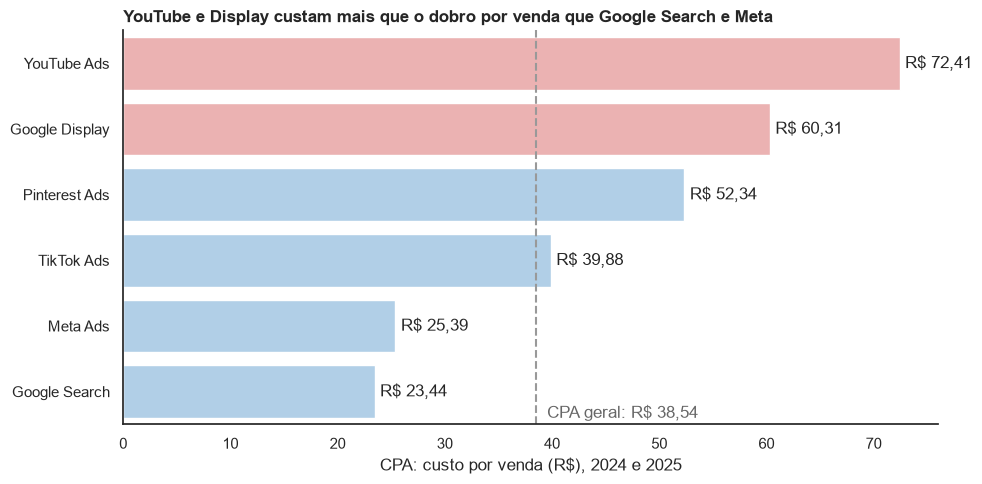

In [30]:
overall_cpa = channel_results['spend'].sum() / channel_results['conversions'].sum()
worst_channels = channel_results['channel_name'].head(2).tolist()
colors = {name: '#f4a9a8' if name in worst_channels else '#a8d0f0' for name in channel_results['channel_name']}

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=channel_results, x='cpa', y='channel_name', hue='channel_name', palette=colors, legend=False, ax=ax)

for container in ax.containers:
    labels = [f'R$ {value:.2f}'.replace('.', ',') for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=4)

ax.axvline(overall_cpa, color='#999999', linestyle='--')
ax.text(overall_cpa + 1, 5.4, f'CPA geral: R$ {overall_cpa:.2f}'.replace('.', ','), color='#666666')

ax.set_title('YouTube e Display custam mais que o dobro por venda que Google Search e Meta', loc='left', fontweight='bold')
ax.set_xlabel('CPA: custo por venda (R$), 2024 e 2025')
ax.set_ylabel('')
sns.despine()
plt.tight_layout()
plt.show()

**Observações da Pergunta 1:**

**Fatos:**
- Em 2024 e 2025 a Social Wave investiu **3,71 milhões** em mídia e conseguiu **96.203 vendas**, um CPA geral de **38,54** e um ROAS geral de **4,75**.
- A verba foi dividida quase igual: cada canal recebeu entre R$ 575 mil e R$ 638 mil. Mesmo com investimentos parecidos, os resultados são muito diferentes.
- **Google Search** (CPA 23,44, ROAS 8,97) e **Meta Ads** (CPA 25,39, ROAS 7,07) são os mais eficientes. Juntos trazem 51% das vendas com 33% da verba.
- **YouTube Ads** (CPA 72,41, ROAS 2,63) e **Google Display** (CPA 60,31, ROAS 2,81) são os menos eficientes. Cada venda custa mais que o dobro.

**Hipóteses (a confirmar nas próximas perguntas):**
- YouTube e Display podem estar **saturados**: recebem mais verba do que conseguem converter bem.
- Search e Meta podem ter **espaço para crescer**: se receberem mais verba, talvez continuem com CPA baixo.

**Recomendação inicial:** não cortar canais ainda. O CPA médio mostra o passado, mas não diz quanto cada canal renderia com **um real a mais**. Essa é a pergunta 4 (saturação), que vai guiar a redistribuição.